In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats


In [3]:
df=pd.read_csv("/home/ammarkhalid/Machine Learning/100 days of Machine Learning/Power Transformer/Dataset/concrete_data.csv")

In [4]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(df.drop(columns=['Strength']),df['Strength'],test_size=0.2,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((824, 8), (206, 8), (824,), (206,))

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

ct=ColumnTransformer(transformers=[("Z-score Normalization",StandardScaler(),slice(None,None))],remainder='passthrough')

x_train_scaled=ct.fit_transform(x_train)
x_test_scaled=ct.transform(x_test)


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr=LinearRegression()
lr.fit(x_train,y_train)

y_pred=lr.predict(x_test)

print("R2 Score: ",r2_score(y_test,y_pred))

R2 Score:  0.627553179231485


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr=LinearRegression()
lr.fit(x_train_scaled,y_train)

y_pred=lr.predict(x_test_scaled)

print("R2 Score: ",r2_score(y_test,y_pred))

R2 Score:  0.627553179231485


In [19]:
from sklearn.model_selection import cross_val_score
x=df.drop(columns=['Strength'])
y=df['Strength']

np.mean(cross_val_score(lr,x,y,scoring='r2'))

np.float64(0.4609940491662866)

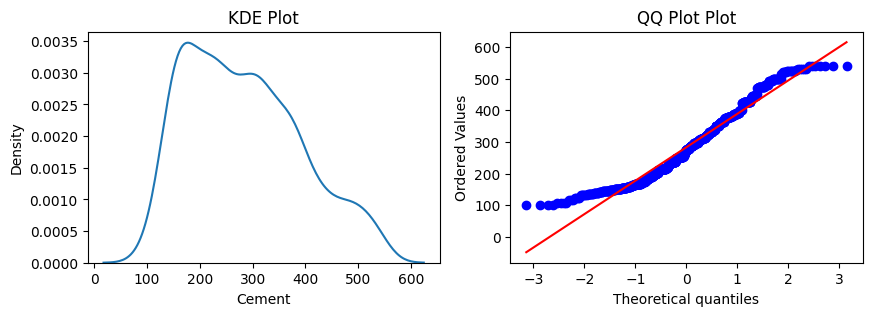

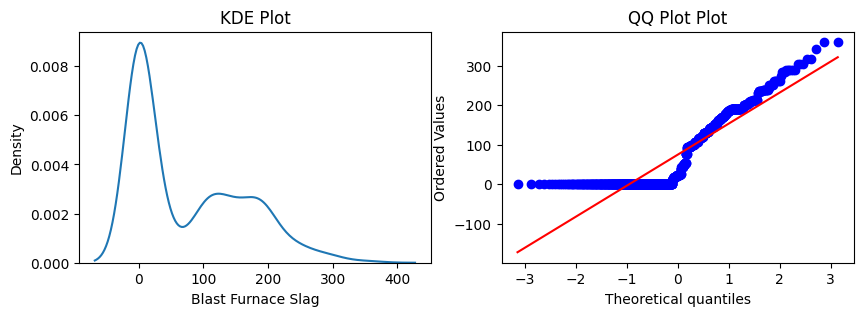

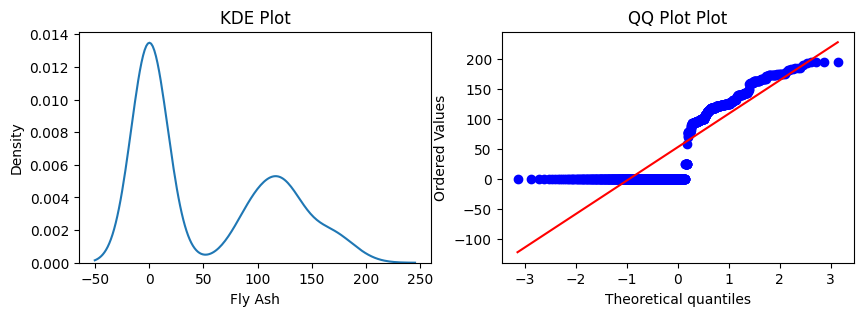

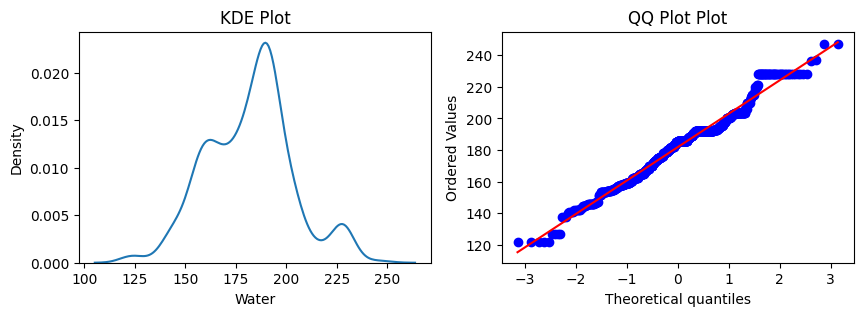

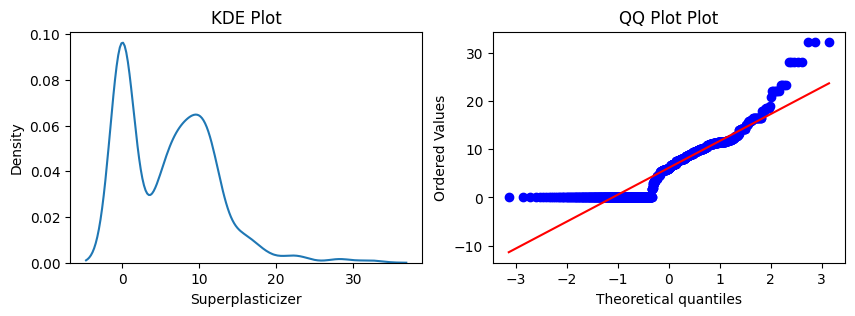

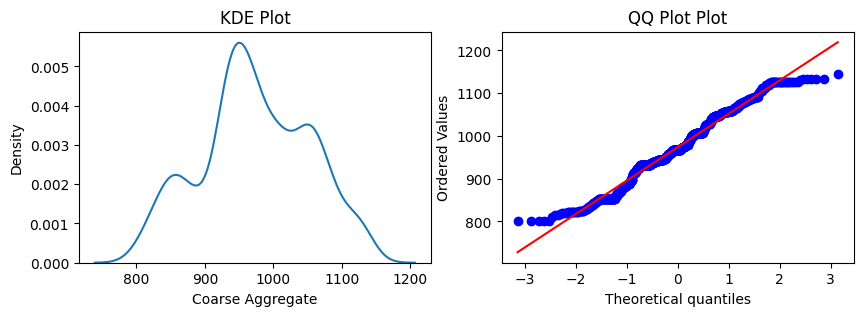

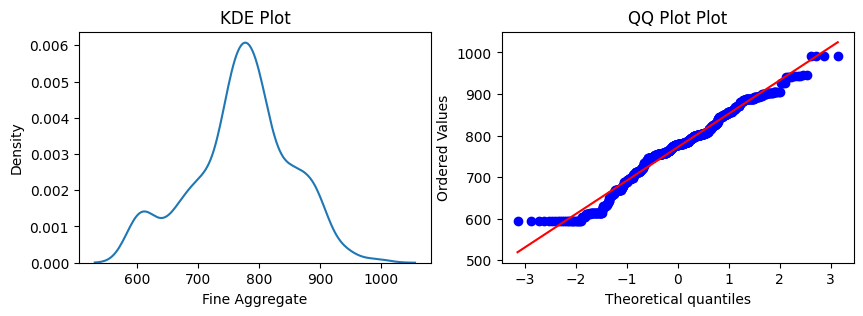

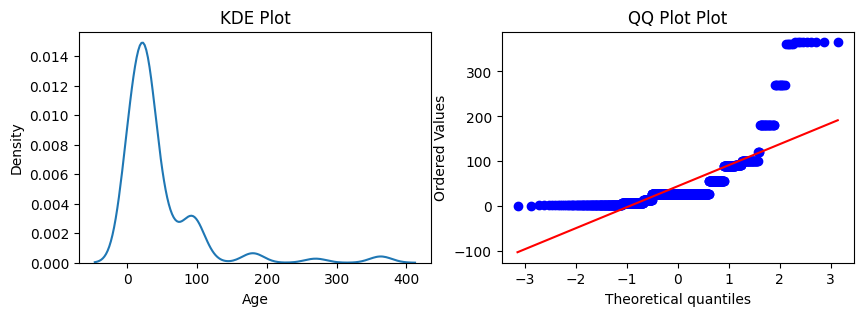

In [26]:
%matplotlib inline
for col in x_train.columns:
    fig,axis=plt.subplots(1,2,figsize=(10,3))
    sns.kdeplot(data=x_train,x=col,ax=axis[0])
    axis[0].set_title("KDE Plot")

    stats.probplot(x_train[col],dist='norm',plot=plt)
    axis[1].set_title("QQ Plot Plot")

    plt.show()


    

### Performing transformation

In [30]:
from sklearn.preprocessing import PowerTransformer

pt=PowerTransformer(method='box-cox') # bydefault its yeo-johnson and by default it also normalizes the data

x_train_transformed=pt.fit_transform(x_train+0.0000000000001)
x_test_transformed=pt.transform(x_test+0.0000000000001)

In [31]:
lr.fit(x_train_transformed,y_train)
y_pred2=lr.predict(x_test_transformed)
print("R2 Score: ",r2_score(y_test,y_pred2))

R2 Score:  0.802563437501849


In [34]:
np.mean(cross_val_score(lr,x_train_transformed,y_train,scoring='r2'))

np.float64(0.791847544394331)

### we can perform same yeo-johnson transformation and it usually gives better results